# Tests (Member C)

Proves that Part 1 (data) and Part 2 (CLIP embeddings) work, and feeds the "Sample testings" section of the report.

Needs `data/subset.csv`, `data/processed/` (run `python src/data.py`) and `src/embed.py`. Uses `data/embeddings.pt` when
it exists, otherwise encodes the captions here. Every check is recorded, so one failure does not hide the others; the
summary at the end lists them all and fails the notebook if any did not pass.

In [1]:
import os, sys, textwrap, warnings
from collections import Counter
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from PIL import Image

import embed
from data import clean_caption

transformers.utils.logging.disable_progress_bar()
results = []

def check(name, passed, detail=""):
    results.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(f"{results[-1]['result']}  {name}  {detail}")

## 1. Dataset

In [2]:
# keep_default_na=False: an empty caption stays "" and a caption like "null" is not read as missing
df = pd.read_csv(ROOT / "data" / "subset.csv", keep_default_na=False)
paths = [ROOT / p for p in df["processed_path"]]
missing = [p.name for p in paths if not p.exists()]
sizes = Counter()
for p in paths:
    if p.exists():
        with Image.open(p) as im:
            sizes[(im.size, im.mode)] += 1

empty = df["caption"].str.strip().eq("").sum()
unclean = (df["caption"] != df["caption"].map(clean_caption)).sum()

check("subset has 2,000 rows", len(df) == 2000, f"{len(df)} rows")
check("image ids are unique", df["image_id"].is_unique, f"{df['image_id'].duplicated().sum()} duplicates")
check("no missing images", not missing, f"{len(missing)} missing")
check("no empty captions", empty == 0, f"{empty} empty")
check("no duplicate captions", df["caption"].is_unique, f"{df['caption'].duplicated().sum()} duplicates")
check("captions are cleaned", unclean == 0, f"{unclean} not lowercase/tidy")
check("all 80 classes present", df["category"].nunique() == 80, f"{df['category'].nunique()} classes")
check("every image is 512x512 RGB", set(sizes) == {((512, 512), "RGB")}, f"{dict(sizes)}")

PASS  subset has 2,000 rows  2000 rows
PASS  image ids are unique  0 duplicates
PASS  no missing images  0 missing
PASS  no empty captions  0 empty
PASS  no duplicate captions  0 duplicates
PASS  captions are cleaned  0 not lowercase/tidy
PASS  all 80 classes present  80 classes
PASS  every image is 512x512 RGB  {((512, 512), 'RGB'): 2000}


### Class balance

Information, not a pass/fail check. The sampler takes 25 images per class, but a class with fewer than 25 images in
COCO val2017 contributes all it has, and the shortfall is filled from the common classes.

In [3]:
counts = df["category"].value_counts()
print(f"images per class: min {counts.min()}, median {counts.median():.0f}, max {counts.max()}")
print("classes under 25:", counts[counts < 25].to_dict())

images per class: min 8, median 25, max 27
classes under 25: {'hair drier': 9, 'toaster': 8}


## 2. Embeddings

In [4]:
tokenizer, encoder = embed.load_text_encoder()
saved = ROOT / "data" / "embeddings.pt"
if saved.exists():
    e = embed.load_embeddings(saved)
    hidden, pooled = e["hidden"].float(), e["pooled"].float()
    check("saved embeddings match subset.csv", e["caption"] == df["caption"].tolist())
else:
    hidden, pooled = embed.encode(df["caption"], tokenizer, encoder)

check("hidden shape is N x 77 x 768", hidden.shape == (len(df), 77, 768), f"{tuple(hidden.shape)}")
check("pooled shape is N x 768", pooled.shape == (len(df), 768), f"{tuple(pooled.shape)}")
check("no NaN or Inf values", bool(hidden.isfinite().all() and pooled.isfinite().all()))

PASS  saved embeddings match subset.csv  
PASS  hidden shape is N x 77 x 768  (2000, 77, 768)
PASS  pooled shape is N x 768  (2000, 768)


PASS  no NaN or Inf values  


### Related captions score higher than unrelated ones

First on hand-written triples (anchor, related, unrelated), then across the dataset: a caption should on average sit
closer to captions of its own COCO class than to captions of other classes. Cosine similarity on the pooled embedding.

In [5]:
triples = [
    ("a giraffe eating leaves from a tree", "a tall giraffe reaching up to the branches", "a laptop on a wooden desk"),
    ("a pizza with cheese on a plate", "a slice of pepperoni pizza on a dish", "a skier going down a snowy hill"),
    ("a bus driving down a city street", "a public bus stopped on the road", "a teddy bear sitting on a bed"),
    ("a person flying a kite in a park", "a child with a kite in an open field", "a toilet in a small bathroom"),
    ("two zebras standing in the grass", "a pair of zebras grazing on a plain", "a clock on top of a tower"),
    ("a boat sailing on a lake", "a small sailboat out on the water", "a sandwich and fries on a tray"),
]
rows = []
for anchor, related, unrelated in triples:
    _, p = embed.encode([anchor, related, unrelated], tokenizer, encoder)
    s = embed.cosine_matrix(p)
    rows.append({"anchor": anchor, "related": round(s[0, 1].item(), 3), "unrelated": round(s[0, 2].item(), 3)})
triple_table = pd.DataFrame(rows)
wins = (triple_table["related"] > triple_table["unrelated"]).sum()
check("related beats unrelated on hand-written triples", wins == len(triples), f"{wins}/{len(triples)}")
triple_table

PASS  related beats unrelated on hand-written triples  6/6


,anchor,related,unrelated
0,a giraffe eating leaves from a tree,0.669,0.187
1,a pizza with cheese on a plate,0.671,0.286
2,a bus driving down a city street,0.799,0.267
3,a person flying a kite in a park,0.798,0.248
4,two zebras standing in the grass,0.866,0.203
5,a boat sailing on a lake,0.809,0.283


In [6]:
S = embed.cosine_matrix(pooled).fill_diagonal_(float("nan"))
rows = []
for name in df["category"].unique():
    mask = torch.tensor((df["category"] == name).values)
    rows.append({"category": name, "same": S[mask][:, mask].nanmean().item(), "other": S[mask][:, ~mask].mean().item()})
by_class = pd.DataFrame(rows).set_index("category")
same, other = by_class["same"].mean(), by_class["other"].mean()
wins = (by_class["same"] > by_class["other"]).sum()
check("same class beats other classes on average", same > other, f"{same:.3f} vs {other:.3f}, {wins}/80 classes")
by_class.assign(gap=by_class["same"] - by_class["other"]).sort_values("gap").round(3).head()

PASS  same class beats other classes on average  0.400 vs 0.242, 80/80 classes


,same,other,gap
category,,,
chair,0.236,0.231,0.005
book,0.264,0.236,0.027
person,0.273,0.245,0.028
bottle,0.290,0.251,0.039
backpack,0.290,0.247,0.044


## 3. Sample grid

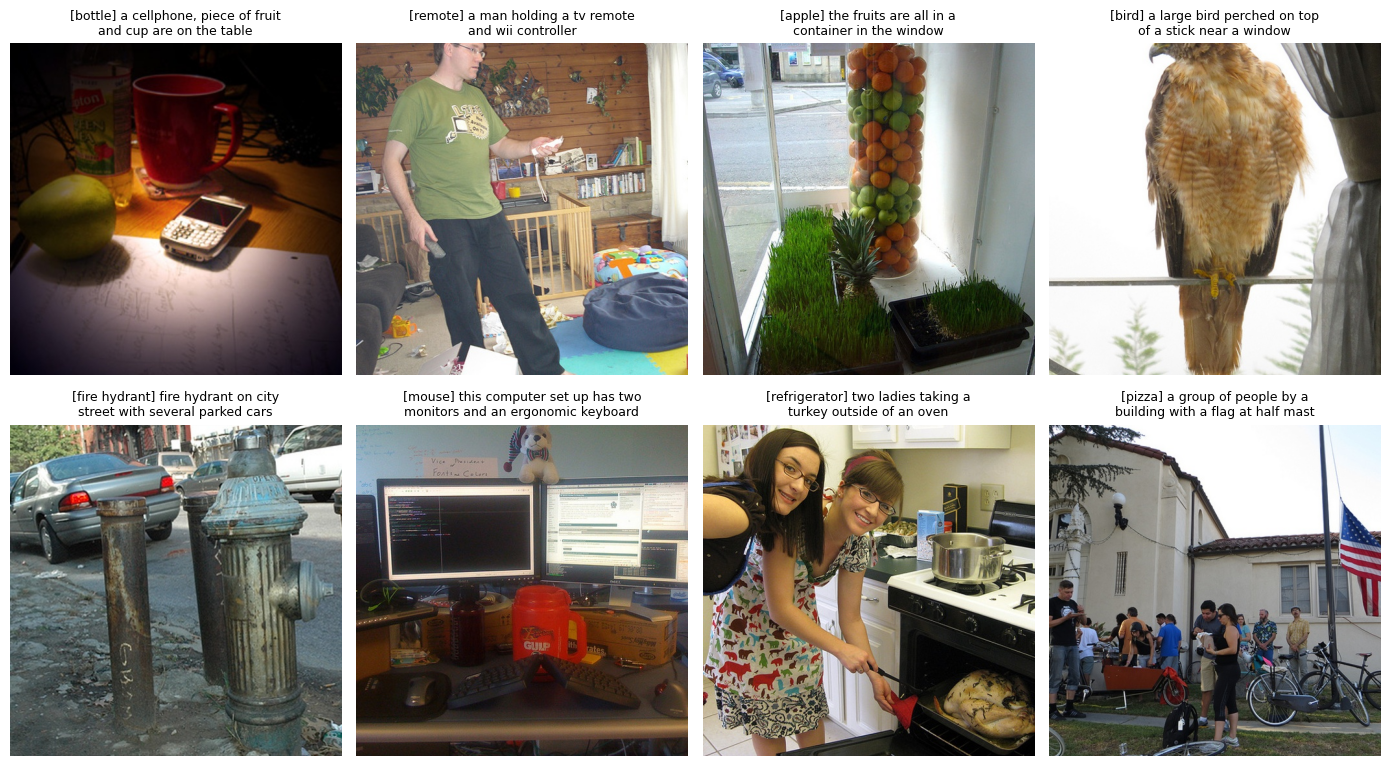

In [7]:
sample = df.sample(8, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, row in zip(axes.flat, sample.itertuples()):
    ax.imshow(Image.open(ROOT / row.processed_path))
    ax.set_title(textwrap.fill(f"[{row.category}] {row.caption}", 36), fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Summary

In [8]:
summary = pd.DataFrame(results)
display(summary)
assert (summary["result"] == "PASS").all(), summary[summary["result"] == "FAIL"]["check"].tolist()
print(f"all {len(summary)} checks passed")

,check,result,detail
0,"subset has 2,000 rows",PASS,2000 rows
1,image ids are unique,PASS,0 duplicates
2,no missing images,PASS,0 missing
3,no empty captions,PASS,0 empty
4,no duplicate captions,PASS,0 duplicates
5,captions are cleaned,PASS,0 not lowercase/tidy
6,all 80 classes present,PASS,80 classes
7,every image is 512x512 RGB,PASS,"{((512, 512), 'RGB'): 2000}"
8,saved embeddings match subset.csv,PASS,
9,hidden shape is N x 77 x 768,PASS,"(2000, 77, 768)"


all 14 checks passed
